# 3B VAE — Kod, Mantık ve Reconstruction Teşhisi

## Kurulum — kütüphaneler ve dosya yolları

Aşağıdaki hücre gerekli kütüphaneleri yükler ve **dosya yollarını değişken olarak** tanımlar.
Hocam siz kendi bilgisayarınızdaki pathlere göre `VAL_NPZ_PATH` ve `CKPT_PATH`'i değiştirebilirsiniz.

**Canlı teşhis (Bölüm 5) için gereken dosyalar:**
- `outputs/volumes/val.npz` — precomputed 64³ doğrulama (val) hacimleri.
  `scripts/precompute_volumes.py` ile RAOS NIfTI etiketlerinden üretilir (karaciğer
  bbox'ı kırpılıp 64³'e yeniden boyutlandırılmış ikili maskeler).
- `outputs/checkpoints/vae3d_best_latent64.pt` — eğitilmiş 3B VAE ağırlıkları
  (`scripts/train_vae3d.py` ile eğitilir).

Bu dosyalar **yoksa** Bölüm 4 rastgele ağırlıkla çalışır, Bölüm 5 ise önceden
hesaplanmış sonuçları basar.


In [ ]:
import os
import numpy as np
import torch
from torch import Tensor, nn
import torch.nn.functional as F
import matplotlib.pyplot as plt
import math

#VAL_NPZ_PATH = "outputs/volumes/val.npz"                     # precomputed 64^3 val hacimleri
VAL_NPZ_PATH = "C:/Users/ahmet.yaylalioglu/Desktop/phd_studies_anatomy/projects/segquality/outputs/volumes/val.npz"
#CKPT_PATH    = "outputs/checkpoints/vae3d_best_latent64.pt"  # egitilmis 3B VAE agirliklari
CKPT_PATH    = "C:/Users/ahmet.yaylalioglu/Desktop/phd_studies_anatomy/projects/segquality/outputs/checkpoints/vae3d_last_latent64.pt"  # egitilmis 3B VAE agirliklari
K    = 20   # teshiste kullanilacak karaciger sayisi
SEED = 42   # tekrar-uretilebilir secim

device = "cuda" if torch.cuda.is_available() else "cpu"
print("torch", torch.__version__, "| cihaz:", device)
print("val.npz     var mi:", os.path.exists(VAL_NPZ_PATH))
print("checkpoint  var mi:", os.path.exists(CKPT_PATH))

torch 2.7.1+cu118 | cihaz: cuda
val.npz     var mi: True
checkpoint  var mi: True


## Bölüm 1 — Ne yapıyoruz?

**Amaç: ground-truth (uzman çizimi) olmadan segmentasyon kalitesini tahmin etmek.**
Klinikte bir organ segmentasyonunun (ör. karaciğer maskesi) ne kadar iyi olduğunu
bilmek isteriz, ama elimizde çoğu zaman "doğru cevap" (ground-truth) yoktur. Biz de
kaliteyi **ground-truth'a ihtiyaç duymadan** tahmin eden bir yöntem geliştiriyoruz.

**3B VAE'nin rolü:** Bir VAE'yi (Variational Autoencoder) yalnızca **sağlam, normal
karaciğer hacimleri** ile eğitiriz. VAE karaciğer hacmini küçük bir "latent" koda
sıkıştırır, sonra geri açar (reconstruction). Sadece normal şekli öğrendiği için:
**normal bir maske → iyi reconstruct edilir; bozuk/hatalı bir maske → kötü reconstruct
edilir.** Böylece *reconstruction hatası* bir **kalite ölçüsü** olur. Bu notebookta o 3B
VAE tarafından üretilen reconstruction'ların neden birbirine benzediğini
(mean-reversion) teşhis ediyoruz.


## Bölüm 2 — 3B VAE mimarisi

Akış (metin şema):

```
   girdi (1, 1, 64, 64, 64)   ->  ENCODER  ->  latent darboğaz  ->  DECODER  ->  çıktı (1, 1, 64, 64, 64)
   ikili maske                    Conv3d x4      mu, logvar (64)     ConvT3d x4    logit -> sigmoid
                                  64->32->16->8->4                   4->8->16->32->64
```

- **Encoder:** dört `Conv3d` katmanı hacmi her adımda yarıya indirir
  (64→32→16→8→4), kanal sayısını artırır. Sonunda 64 boyutlu `mu` ve `logvar` üretir.
- **Latent darboğaz (bottleneck):** Tüm hacim yalnızca **64 sayıya** sıkışır. Bu darboğaz
  kritiktir: model her şeyi ezberleyemez, **karaciğerin genel şeklini** öğrenmek zorunda
  kalır. Darboğaz sayesinde "normal şekil önsel bilgisi" (shape prior) oluşur.
- **Decoder:** dört `ConvTranspose3d` katmanı latent kodu tekrar 64³ hacme açar (logit üretir;
  olasılık için `sigmoid` uygulanır).


In [2]:
# Kanal çarpanları: base_channels'in kaç katı. Uzunluk = stride-2 kademe sayısı.
# 4 kademe: 64 -> 32 -> 16 -> 8 -> 4 (her kademe eksenleri yarıya böler).
_CHANNEL_MULTS = (1, 2, 4, 8)


class ConvVAE3D(nn.Module):
    """Tek kanallı ikili hacimler için evrişimli VAE (models/vae3d.py ile aynı mantık)."""

    def __init__(self, latent_dim=64, base_channels=16, input_size=(64, 64, 64), in_channels=1):
        super().__init__()
        self.latent_dim = int(latent_dim)
        self.base_channels = int(base_channels)
        self.input_size = tuple(int(s) for s in input_size)
        self.in_channels = int(in_channels)

        n_stages = len(_CHANNEL_MULTS)          # 4 kademe
        divisor = 2 ** n_stages                 # 16 = 2^4 (toplam küçültme oranı)
        # Darboğazdaki uzamsal boyut (hard-code değil, hesaplanır): 64/16 = 4 -> (4,4,4)
        self._feat_dhw = tuple(s // divisor for s in self.input_size)
        channels = [self.base_channels * m for m in _CHANNEL_MULTS]  # [16, 32, 64, 128]
        self._bottleneck_channels = channels[-1]                     # 128
        # Darboğazın düzleştirilmiş uzunluğu: 128 * 4 * 4 * 4
        self._flat_dim = self._bottleneck_channels * math.prod(self._feat_dhw)

        self.encoder = self._build_encoder(channels)
        self.fc_mu = nn.Linear(self._flat_dim, self.latent_dim)       # latent ortalama mu
        self.fc_logvar = nn.Linear(self._flat_dim, self.latent_dim)   # latent log-varyans
        self.fc_decode = nn.Linear(self.latent_dim, self._flat_dim)   # latent -> darboğaz
        self.decoder = self._build_decoder(channels)

    def _build_encoder(self, channels):
        layers = []
        prev = self.in_channels
        for ch in channels:
            # Her blok: Conv3d hacmi yarıya indirir (stride=2), sonra normalizasyon + aktivasyon
            layers += [
                nn.Conv3d(prev, ch, kernel_size=4, stride=2, padding=1),  # 64->32->16->8->4
                nn.BatchNorm3d(ch),
                nn.LeakyReLU(0.2, inplace=True),
            ]
            prev = ch
        return nn.Sequential(*layers)

    def _build_decoder(self, channels):
        layers = []
        rev = list(reversed(channels))  # [128, 64, 32, 16]
        for prev, ch in zip(rev[:-1], rev[1:]):
            # Her blok: ConvTranspose3d hacmi iki katına çıkarır (4->8->16->32)
            layers += [
                nn.ConvTranspose3d(prev, ch, kernel_size=4, stride=2, padding=1),
                nn.BatchNorm3d(ch),
                nn.LeakyReLU(0.2, inplace=True),
            ]
        # Son kademe: 32->64'e çıkarır ve LOGIT üretir (BatchNorm/aktivasyon YOK)
        layers.append(nn.ConvTranspose3d(rev[-1], self.in_channels, kernel_size=4, stride=2, padding=1))
        return nn.Sequential(*layers)

    def _encode_dist(self, x):
        # Encoder'dan geçir, düzleştir, latent dağılım parametrelerini (mu, logvar) döndür
        h = self.encoder(x)
        h = torch.flatten(h, start_dim=1)
        return self.fc_mu(h), self.fc_logvar(h)

    def encode(self, x):
        # Yalnızca posterior ortalamayı (mu) döndürür — deterministik latent kod
        mu, _ = self._encode_dist(x)
        return mu

    def decode(self, z):
        # Latent kodu darboğaz şekline aç, decoder'dan geçir, LOGIT döndür (sigmoid YOK)
        h = self.fc_decode(z)
        h = h.view(-1, self._bottleneck_channels, *self._feat_dhw)
        return self.decoder(h)

    def reparameterize(self, mu, logvar):
        # Reparametrizasyon hilesi: eğitimde z = mu + eps*std (gradyan akabilsin),
        # değerlendirmede (eval) deterministik olsun diye doğrudan mu döner.
        if not self.training:
            return mu
        std = torch.exp(0.5 * logvar)      # logvar -> standart sapma
        eps = torch.randn_like(std)        # standart normal gürültü
        return mu + eps * std

    def forward(self, x):
        # Tam geçiş: kodla -> örnekle -> çöz. Ham logit + (mu, logvar) döner.
        mu, logvar = self._encode_dist(x)
        z = self.reparameterize(mu, logvar)
        logits = self.decode(z)
        return logits, mu, logvar

    def reconstruct(self, x):
        # Değerlendirme/önizleme için reconstruction OLASILIKLARI (sigmoid uygulanmış)
        logits, _, _ = self.forward(x)
        return torch.sigmoid(logits)


print("ConvVAE3D tanımlandı.")

ConvVAE3D tanımlandı.


## Bölüm 3 — Kayıp (loss) fonksiyonu

VAE iki terimle eğitilir:

1. **Reconstruction kaybı** — çıktının girdiye ne kadar benzediği. İki bileşenin toplamı:
   - **BCE** (`BCEWithLogitsLoss`): piksel/voksel bazında olasılık hatası, sayısal olarak kararlı.
   - **soft-Dice**: örtüşme (overlap) temelli; küçük organ / dengesiz sınıf durumunda BCE'yi
     tamamlar. İkisini birlikte kullanmak hem voksel-bazlı hem şekil-bazlı sinyal verir.
2. **KL ıraksaması** — latent dağılımı standart normale (N(0, I)) yaklaştırır; latent uzayı
   düzenli/sürekli tutar. **β (beta)** bu terimin ağırlığıdır: yüksek β latent'i çok düzenler
   ama *posterior collapse* (latent'in tamamen yok sayılması) riskini artırır; bu yüzden düşük
   tutulur (β=0.1) ve ilk birkaç epoch'ta 0'dan hedefe **ısıtılır (warmup)**.


In [3]:
def vae_loss(logits, target, mu, logvar, beta=0.1, dice_weight=1.0):
    """Reconstruction (BCE + soft-Dice) + beta * KL. models/losses ile aynı mantık."""
    # (1a) Voksel-bazlı BCE — logit üzerinden, sayısal kararlı
    bce = F.binary_cross_entropy_with_logits(logits, target)

    # (1b) soft-Dice — olasılıklar üzerinden örtüşme; +1 düzeltmesi 0/0'ı önler
    probs = torch.sigmoid(logits)
    dims = tuple(range(1, target.dim()))          # kanal+uzamsal eksenler (batch hariç)
    inter = (probs * target).sum(dims)
    denom = probs.sum(dims) + target.sum(dims)
    dice = (2 * inter + 1) / (denom + 1)
    dice_loss = (1.0 - dice).mean()

    recon = bce + dice_weight * dice_loss

    # (2) KL ıraksaması: latent'i N(0, I)'ya yaklaştırır
    kl = -0.5 * torch.mean(1 + logvar - mu.pow(2) - logvar.exp())

    total = recon + beta * kl
    return total, {"bce": float(bce), "dice_loss": float(dice_loss), "kl": float(kl)}


print("vae_loss tanımlandı.")

vae_loss tanımlandı.


## Bölüm 4 — Canlı demo (veri gerektirmez)

Küçük bir sentetik 64³ küre üretip modelden geçiriyoruz ve **şekil akışını** basıyoruz:
`girdi (1,1,64,64,64) → latent (1,64) → çıktı (1,1,64,64,64)`.

Eğitilmiş checkpoint varsa onunla, yoksa **rastgele ağırlıklı** modelle çalışır.
Amaç akışı canlı görmek; anlamlı reconstruction için eğitilmiş ağırlık gerekir.


In [4]:
# Modeli kur (64^3, latent 64) ve varsa egitilmis agirliklari yukle
model = ConvVAE3D(latent_dim=64, base_channels=16, input_size=(64, 64, 64)).to(device)
if os.path.exists(CKPT_PATH):
    ckpt = torch.load(CKPT_PATH, map_location=device, weights_only=False)
    model.load_state_dict(ckpt["model_state"])
    print("Egitilmis agirliklar yuklendi:", CKPT_PATH, "| epoch", ckpt.get("epoch"))
else:
    print("UYARI: checkpoint bulunamadi -> RASTGELE agirlikli model kullaniliyor.")
    print("       (Akis dogru gorunecek ama reconstruction anlamli olmayacak.)")
    print("       Egitmek icin: scripts/train_vae3d.py")
model.eval()

# Sentetik 64^3 kure (merkez 32, yaricap 18)
zz, yy, xx = np.ogrid[:64, :64, :64]
sphere = ((zz - 32) ** 2 + (yy - 32) ** 2 + (xx - 32) ** 2) <= 18 ** 2
x = torch.from_numpy(sphere.astype("float32"))[None, None].to(device)  # (1,1,64,64,64)

with torch.no_grad():
    mu = model.encode(x)             # (1, 64)
    recon = model.reconstruct(x)     # (1, 1, 64, 64, 64)

print("girdi   (ikili maske) :", tuple(x.shape))
print("latent  (mu)          :", tuple(mu.shape))
print("cikti   (reconstruction):", tuple(recon.shape))

Egitilmis agirliklar yuklendi: C:/Users/ahmet.yaylalioglu/Desktop/phd_studies_anatomy/projects/segquality/outputs/checkpoints/vae3d_last_latent64.pt | epoch 97
girdi   (ikili maske) : (1, 1, 64, 64, 64)
latent  (mu)          : (1, 64)
cikti   (reconstruction): (1, 1, 64, 64, 64)


## Bölüm 5 — SORUNUMUZ: reconstruction'lar neden birbirine benziyor?

**Fatmatülzehra Hoca'nın gözlemi:** 3B VAE reconstruction önizlemelerinde farklı karaciğerlerin
reconstruction'ları "sütun bazlı aynı" görünüyor — sanki model herkese aynı jenerik
şekli üretiyor (olası **mean-reversion / mode-collapse**).

Bunu üç ölçümle test ediyoruz (görsel izlenime güvenmeden, sayılarla):

1. **Cross-reconstruction Dice matrisi:** `M[i,j] = Dice(recon_i, input_j)`. Köşegen
   (bir reconstruction'ın *kendi* girdisiyle örtüşmesi) köşegen-dışına göre belirgin
   yüksekse (`ratio = köşegen/köşegen-dışı > 1`), reconstruction girdiye özgüdür. `ratio ≈ 1`
   ise model herkese aynı şekli üretiyordur.
2. **Input-pairwise vs recon-pairwise Dice:** reconstruction'lar birbirine, girdilerin
   birbirine benzediğinden *daha çok* benziyorsa (recon-pairwise > input-pairwise), model
   çeşitliliği aktif olarak azaltıyordur — çok net olarak mean-reversion işareti.
3. **Latent çeşitliliği:** `mu` vektörleri arası ortalama uzaklık ve ölü boyut sayısı
   (std ≈ 0 olan latent boyutları). Çökmüş latent, mean-reversion'ın mekanizmasıdır.

Aşağıdaki hücre, dosyalar varsa teşhisi **canlı** çalıştırır; yoksa önceden hesaplanmış
sonuçları basar.


K = 20 karaciger (seed 42)
(1) diag_mean = 0.8053 | offdiag_mean = 0.8019 | ratio = 1.0043
(2) input_pairwise_dice = 0.7326 | recon_pairwise_dice = 0.9932
    delta (recon - input) = +0.2606
(3) mean_latent_L2 = 0.3864 | dead_dims = 0/64
YORUM: ratio ~= 1  ->  mean-reversion GERCEK (recon girdiye ozgu degil).


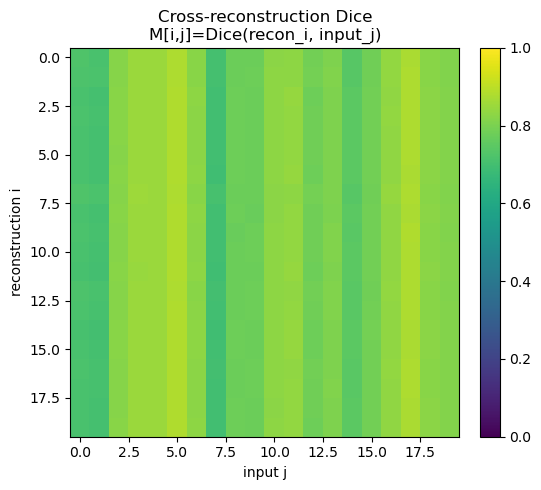

In [5]:
def dice_np(a, b):
    """İki ikili hacmin Dice örtüşmesi (ikisi de boşsa 1.0)."""
    a = a.astype(bool); b = b.astype(bool)
    tot = int(a.sum()) + int(b.sum())
    if tot == 0:
        return 1.0
    return 2.0 * int(np.logical_and(a, b).sum()) / tot


if os.path.exists(VAL_NPZ_PATH) and os.path.exists(CKPT_PATH):
    # --- CANLI TESHIS ---
    with np.load(VAL_NPZ_PATH, allow_pickle=False) as d:
        vols = d["volumes"]                                  # (N, 64, 64, 64) ikili
    rng = np.random.default_rng(SEED)
    k = min(K, len(vols))
    idx = sorted(rng.choice(len(vols), size=k, replace=False).tolist())
    masks = vols[idx].astype("float32")
    xb = torch.from_numpy(masks)[:, None].to(device)         # (k,1,64,64,64)

    model.eval()
    with torch.no_grad():
        probs = model.reconstruct(xb).cpu().numpy()[:, 0]    # (k,64,64,64) olasilik
        mu = model.encode(xb).cpu().numpy()                  # (k,64)
    inputs_bin = masks > 0.5
    recon_bin = probs > 0.5

    # (1) cross-reconstruction Dice matrisi
    M = np.array([[dice_np(recon_bin[i], inputs_bin[j]) for j in range(k)] for i in range(k)])
    diag = np.diag(M)
    off = M[~np.eye(k, dtype=bool)]
    ratio = float(diag.mean() / off.mean())

    # (2) input- vs recon-pairwise Dice
    def pairwise(bins):
        v = [dice_np(bins[i], bins[j]) for i in range(k) for j in range(i + 1, k)]
        return float(np.mean(v))
    input_pw = pairwise(inputs_bin)
    recon_pw = pairwise(recon_bin)

    # (3) latent cesitliligi
    l2 = [float(np.linalg.norm(mu[i] - mu[j])) for i in range(k) for j in range(i + 1, k)]
    dead = int((mu.std(axis=0) < 0.01).sum())

    print("=" * 60)
    print(f"K = {k} karaciger (seed {SEED})")
    print(f"(1) diag_mean = {diag.mean():.4f} | offdiag_mean = {off.mean():.4f} | ratio = {ratio:.4f}")
    print(f"(2) input_pairwise_dice = {input_pw:.4f} | recon_pairwise_dice = {recon_pw:.4f}")
    print(f"    delta (recon - input) = {recon_pw - input_pw:+.4f}")
    print(f"(3) mean_latent_L2 = {np.mean(l2):.4f} | dead_dims = {dead}/{mu.shape[1]}")
    print("=" * 60)
    if ratio < 1.15:
        print("YORUM: ratio ~= 1  ->  mean-reversion GERCEK (recon girdiye ozgu degil).")
    else:
        print("YORUM: ratio > 1  ->  reconstruction girdiye ozgu; mean-reversion yok.")

    # isi haritasi (inline)
    plt.figure(figsize=(6, 5))
    im = plt.imshow(M, cmap="viridis", vmin=0, vmax=1)
    plt.colorbar(im, fraction=0.046, pad=0.04)
    plt.title("Cross-reconstruction Dice\nM[i,j]=Dice(recon_i, input_j)")
    plt.xlabel("input j"); plt.ylabel("reconstruction i")
    plt.tight_layout(); plt.show()

else:
    # --- DOSYA YOK: onceden hesaplanmis sonuclari goster (cokme yok) ---
    print("UYARI: Canli teshis icin gerekli dosyalar bulunamadi, atlaniyor.")
    print("  gerekli:", VAL_NPZ_PATH, "->", os.path.exists(VAL_NPZ_PATH))
    print("  gerekli:", CKPT_PATH, "->", os.path.exists(CKPT_PATH))
    print("  Uretmek icin: scripts/precompute_volumes.py (val.npz) ve scripts/train_vae3d.py (checkpoint)")
    print()
    print("ONCEDEN HESAPLANMIS SONUCLAR (K=20, seed 42):")
    print("  (1) diag_mean = 0.808 | offdiag_mean = 0.804 | ratio = 1.005")
    print("  (2) input_pairwise_dice = 0.733 | recon_pairwise_dice = 0.992 (delta +0.259)")
    print("  (3) dead_dims = 0/64 | encoder Spearman(input-Dice, latent-uzaklik) = -0.857")
    print("  -> ratio ~= 1 ve recon-pairwise >> input-pairwise: mean-reversion GERCEK.")

### Bölüm 5b — Görsel: karaciğer maskeleri ve reconstruction'ları

Aşağıdaki tek hücre, seçilen karaciğer maskelerini **ortogonal kesitlerle** (aksiyel/koronal/sagital)
görselleştirir: solda **girdi maskesi**, sağda o girdinin **VAE reconstruction**'ı. Her satırın
etiketi istenen bilgileri taşır:

- **3B: evet** — gösterilen her şey 3B bir hacmin merkez kesitleridir (2B slice değil).
- **durum: temiz / BOZULMUS** — maske orijinal (temiz) mi, yoksa bilerek bozulmuş mu.
- **hasta / hacim** — hangi hastaya ve hangi hacme (val indeksine) ait. Aynı satırdaki girdi ve
  recon **aynı hasta / aynı hacimdir**; farklı satırlar **farklı hastalardır**.
- **Dice** — girdinin kendi reconstruction'ına örtüşmesi (self-recon Dice).

Amaç danışmanın gözlemini gözle doğrulamak: **farklı hastaların girdileri farklı olsa da
reconstruction'ları birbirine çok benzer** (mean-reversion). Son satır, aynı hastanın bozulmuş
(erozyon) hali olup bozuk maskede self-Dice'in düştüğünü — yani kalite sinyalinin kaynağını gösterir.


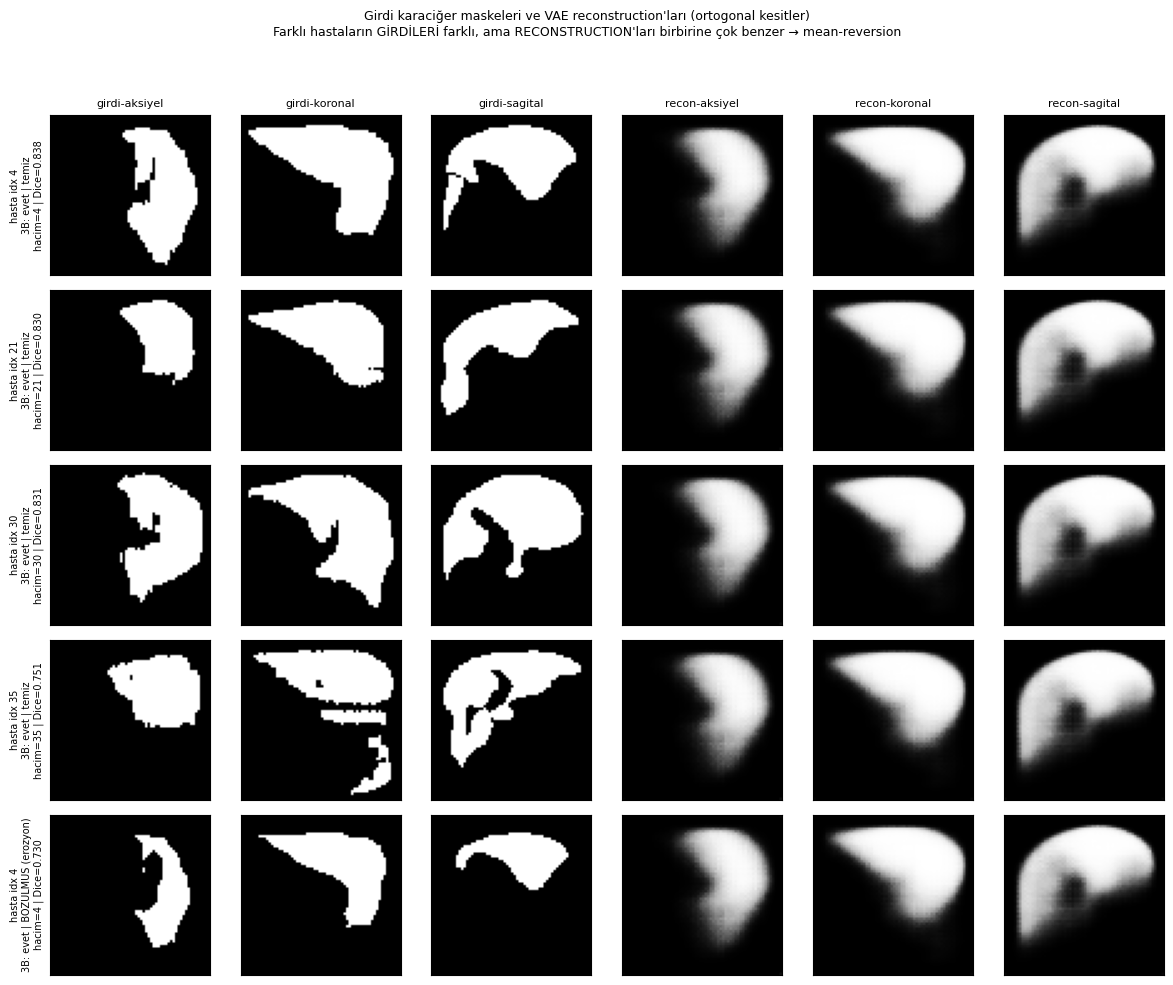

Okuma: her satırda solda 3 girdi kesiti, sağda o girdinin 3 reconstruction kesiti.
Aynı satırdaki girdi ve recon AYNI hasta / AYNI hacimdir (recon = o girdinin modelden geçmiş hali).
Farklı satırlar farklı hastalardır. Son satır aynı hastanın BOZULMUS (erozyon) halidir —
bozuk maskenin self-Dice'i temize göre düşer; kalite sinyali buradan gelir.


In [6]:
# Görsel önizleme: girdi karaciğer maskeleri ve VAE reconstruction'ları (ortogonal kesitler)
# Etiketler her satırda: 3B mi | durum (temiz/BOZULMUS) | hasta | hacim indeksi | self-recon Dice
from scipy.ndimage import binary_erosion

if os.path.exists(VAL_NPZ_PATH) and os.path.exists(CKPT_PATH):
    with np.load(VAL_NPZ_PATH, allow_pickle=False) as d:
        vols = d["volumes"]                       # (N, 64, 64, 64) ikili hacimler

    # Farklı hastalar seç: girdiler FARKLI olmasına rağmen recon'ların benzediğini gözle
    n_show = 4
    rng_v = np.random.default_rng(SEED)
    sel = sorted(rng_v.choice(len(vols), size=n_show, replace=False).tolist())

    # Her satır: (maske, hasta_etiketi, durum, hacim_indeksi)
    # İlk n_show satır temiz val hacimleri; son satır ilk hastanın BOZULMUS (erozyon) hali
    rows = [(vols[i].astype("float32"), f"hasta idx {i}", "temiz", i) for i in sel]
    base = sel[0]
    degraded = binary_erosion(vols[base].astype(bool), iterations=3).astype("float32")
    rows.append((degraded, f"hasta idx {base}", "BOZULMUS (erozyon)", base))

    def ortho(v):
        d, h, w = v.shape
        return [v[d // 2], v[:, h // 2], v[:, :, w // 2]]   # aksiyel, koronal, sagital

    col_titles = ["girdi-aksiyel", "girdi-koronal", "girdi-sagital",
                  "recon-aksiyel", "recon-koronal", "recon-sagital"]
    model.eval()
    fig, axes = plt.subplots(len(rows), 6, figsize=(12, 2 * len(rows)))
    axes = np.atleast_2d(axes)
    for r, (m, pid, durum, vidx) in enumerate(rows):
        x1 = torch.from_numpy(m)[None, None].to(device)      # (1,1,64,64,64)
        with torch.no_grad():
            rec = model.reconstruct(x1).cpu().numpy()[0, 0]  # reconstruction olasiligi
        selfd = dice_np(m > 0.5, rec > 0.5)                  # girdinin kendi recon'una Dice'i
        panels = ortho(m) + ortho(rec)                       # 3 girdi + 3 recon kesiti
        for c, img in enumerate(panels):
            ax = axes[r, c]
            ax.imshow(img, cmap="gray", vmin=0, vmax=1)
            ax.set_xticks([]); ax.set_yticks([])
            if r == 0:
                ax.set_title(col_titles[c], fontsize=8)
        # Sol eksen etiketi: istenen tüm bilgiler
        axes[r, 0].set_ylabel(
            f"{pid}\n3B: evet | {durum}\nhacim={vidx} | Dice={selfd:.3f}", fontsize=7
        )
    fig.suptitle(
        "Girdi karaciğer maskeleri ve VAE reconstruction'ları (ortogonal kesitler)\n"
        "Farklı hastaların GİRDİLERİ farklı, ama RECONSTRUCTION'ları birbirine çok benzer → mean-reversion",
        fontsize=9,
    )
    fig.tight_layout(rect=[0, 0, 1, 0.95])
    plt.show()

    print("Okuma: her satırda solda 3 girdi kesiti, sağda o girdinin 3 reconstruction kesiti.")
    print("Aynı satırdaki girdi ve recon AYNI hasta / AYNI hacimdir (recon = o girdinin modelden geçmiş hali).")
    print("Farklı satırlar farklı hastalardır. Son satır aynı hastanın BOZULMUS (erozyon) halidir —")
    print("bozuk maskenin self-Dice'i temize göre düşer; kalite sinyali buradan gelir.")
else:
    print("UYARI: val.npz veya checkpoint bulunamadı → görsel önizleme atlanıyor (çökme yok).")
    print("  gerekli:", VAL_NPZ_PATH, "->", os.path.exists(VAL_NPZ_PATH))
    print("  gerekli:", CKPT_PATH, "->", os.path.exists(CKPT_PATH))
    print("  Bu hücre girdi maskelerini ve reconstruction'larını ortogonal kesitlerle,")
    print("  3B/temiz-bozuk/hasta/hacim etiketleriyle gösterir; dosyalar hazır olunca çalışır.")


## Bölüm 6 — Sonuç ve yorum

**Bulgu: mean-reversion gerçek.** Ölçümler (K=20, seed 42):

| ölçüt | değer | yorum |
|---|---|---|
| cross-recon `ratio` (köşegen/köşegen-dışı) | **1.005** | ≈1 → recon girdiye özgü değil |
| köşegen vs köşegen-dışı Dice | 0.808 vs 0.804 | bir recon *başka* karaciğerleri kendi girdisi kadar iyi örter |
| input-pairwise Dice | 0.733 | girdiler birbirinden belirgin farklı |
| **recon-pairwise Dice** | **0.992** | reconstruction'lar birbirine neredeyse **aynı** |
| ölü latent boyut | 0 / 64 | latent ölü değil, kullanılıyor |
| encoder: input-Dice ↔ latent-uzaklık (Spearman) | **−0.857** | benzer girdiler latent'te birbirine yakın |

**Mekanizma:** İki katman farklı davranıyor.
- **Encoder sağlam:** benzer girdileri latent uzayında birbirine yakın yerleştiriyor
  (Spearman −0.857), yani karaciğer kimliğini latent'e **doğru yazıyor**.
- **Decoder tembel:** latent'teki bu farkı büyük ölçüde **yok sayıp** herkese jenerik,
  ortalama bir karaciğer şekli üretiyor (recon-pairwise 0.992). Sorun kodlamada değil,
  çözümlemede (decoding).

**Peki korelasyon (ρ≈0.85) neden yine de çalışıyor?** Çünkü model herkese *ortalama
karaciğer şeklini* üretiyor: **iyi/normal bir maske** bu ortalama şekle iyi oturur
(yüksek reconstruction Dice), **bozuk bir maske** oturmaz (düşük Dice). Yani
"ortalama-şekle-benzerlik" işe yarayan bir kalite proxy'sidir. Sonuç olarak yöntem
çalışıyor — ama gücü "girdiye özgü mükemmel reconstruction"dan değil,
"ortalama-şekle-uyum"dan geliyor.


## Bölüm 7 — Çözüm önerileri

Decoder'ın latent'i daha çok kullanması için denenebilecekler (varsayımlarım)

- **Daha büyük latent boyut:** decoder'a daha zengin bilgi taşır — ama tek başına
  mean-reversion'ı çözme garantisi yok.
- **Daha zayıf KL (düşük β):** latent'i daha az düzenleyerek decoder'ın onu daha çok
  kullanmasını teşvik eder — fazla düşürülürse latent uzayı bozulabilir.
- **Daha az agresif sıkıştırma (squash):** eksen-bazlı sıkıştırma bilgi kaybettiriyor
  olabilir; daha yumuşak/oran-koruyan resize denenebilir.
- **Augmentation:** yalnızca ~222 hasta var; rotasyon/flip/elastik deformasyonla
  çeşitliliği artırmak decoder'ı ezberlemek yerine öğrenmeye zorlar.
- **Decoder kapasitesi / skip-connection:** decoder'ı güçlendirmek (ör. U-Net tarzı
  skip bağlantılar) latent'i daha iyi kullanmasını sağlayabilir.
- **Not:** Bu öneriler hipotez; her biri ölçülerek (aynı val seti, aynı `ratio` ve
  cross-recon teşhisi) doğrulanması gerekmektedir.
